In [1]:
import rasterio
import tensorflow as tf
import numpy as np
import geopandas as gpd

print(f"TensorFlow Version: {tf.__version__}")
print(f"Rasterio Version: {rasterio.__version__}")

# Check if TensorFlow detects your local GPU
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"Success! Hardware Acceleration Active. GPU found: {gpu_devices[0].name}")
else:
    print("Running on CPU (Standard execution).")

TensorFlow Version: 2.10.0
Rasterio Version: 1.4.3
Success! Hardware Acceleration Active. GPU found: /physical_device:GPU:0


Loading GeoTIFF and slicing into 32x32 chips...


C:\Users\PC\AppData\Local\Temp\ipykernel_17372\66320932.py:25: RuntimeWarning: Mean of empty slice
  if np.nanmean(valid_mask) > 0.95:


Separating features and enforcing strict target classes...
Features Tensor Shape: (621, 32, 32, 12)
LULC Target Shape: (621, 32, 32)
UHI Target Shape: (621, 32, 32)


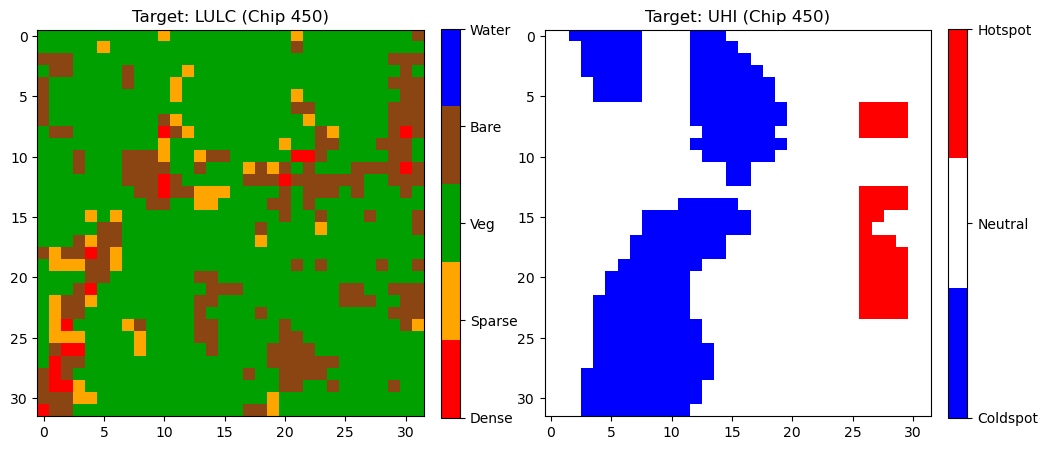

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ==========================================
# 1. SPATIAL CHIP EXTRACTION FUNCTION
# ==========================================
def create_spatial_chips(tiff_path, chip_size=32):
    with rasterio.open(tiff_path) as src:
        image_array = src.read()
        
    # Transpose to (Height, Width, Bands) for CNN
    image_array = np.transpose(image_array, (1, 2, 0))
    height, width, num_bands = image_array.shape
    chips = []
    
    for y in range(0, height - chip_size + 1, chip_size):
        for x in range(0, width - chip_size + 1, chip_size):
            chip = image_array[y:y+chip_size, x:x+chip_size, :]
            
            # Index 14 is your VALID_MASK band
            # Only keep the chip if at least 95% of the pixels are valid satellite data
            valid_mask = chip[:, :, 14]
            if np.nanmean(valid_mask) > 0.95: 
                chips.append(chip)
                
    return np.array(chips)

# ==========================================
# 2. TARGET CLASSIFICATION FUNCTION
# ==========================================
def prepare_targets(chip_tensor):
    """
    Isolates the target bands based on the 2020 GEE export structure:
    Index 12 = UHI_ANOMALY
    Index 13 = LULC (0-4)
    """
    features = chip_tensor[:, :, :, 0:12] # Optical bands, indices, and LST
    uhi_anomaly_raw = chip_tensor[:, :, :, 12]
    lulc_raw = chip_tensor[:, :, :, 13]
    
    # Force strict UHI integers to prevent color overlap
    uhi_classes = np.zeros_like(uhi_anomaly_raw)
    uhi_classes[uhi_anomaly_raw < -1.5] = 0  # Coldspot
    uhi_classes[(uhi_anomaly_raw >= -1.5) & (uhi_anomaly_raw <= 1.5)] = 1 # Neutral
    uhi_classes[uhi_anomaly_raw > 1.5] = 2   # Intense Hotspot
    
    return features, lulc_raw, uhi_classes

# ==========================================
# 3. EXECUTION 
# ==========================================
# Point this to your newly extracted folder
file_path = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\Enugu_2020_COMPLETE_ANALYSIS_STACK.tif"

print("Loading GeoTIFF and slicing into 32x32 chips...")
image_tensor = create_spatial_chips(file_path, chip_size=32)

print("Separating features and enforcing strict target classes...")
X_features, Y_lulc, Y_uhi = prepare_targets(image_tensor)

print(f"Features Tensor Shape: {X_features.shape}")
print(f"LULC Target Shape: {Y_lulc.shape}")
print(f"UHI Target Shape: {Y_uhi.shape}")


## ==========================================
# 4. VISUAL VERIFICATION (CORRECTED)
# ==========================================
# Define strict hex codes matching your GEE script
lulc_colors = ListedColormap(['#FF0000', '#FFA500', '#00A000', '#8B4513', '#0000FF'])
uhi_colors = ListedColormap(['#0000FF', '#FFFFFF', '#FF0000'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Plot the 50th chip in the tensor as a test
chip_index = 450 

im1 = ax1.imshow(Y_lulc[chip_index], cmap=lulc_colors, vmin=0, vmax=4)
ax1.set_title(f"Target: LULC (Chip {chip_index})")
# Changed ax1=ax1 to ax=ax1
cbar1 = plt.colorbar(im1, ax=ax1, ticks=[0, 1, 2, 3, 4], fraction=0.046, pad=0.04)
cbar1.ax.set_yticklabels(['Dense', 'Sparse', 'Veg', 'Bare', 'Water'])

im2 = ax2.imshow(Y_uhi[chip_index], cmap=uhi_colors, vmin=0, vmax=2)
ax2.set_title(f"Target: UHI (Chip {chip_index})")
# Changed ax1=ax2 to ax=ax2
cbar2 = plt.colorbar(im2, ax=ax2, ticks=[0, 1, 2], fraction=0.046, pad=0.04)
cbar2.ax.set_yticklabels(['Coldspot', 'Neutral', 'Hotspot'])

plt.show()

In [5]:
import os
import rasterio

years = [2000, 2005, 2010, 2015, 2020, 2025] 
base_folder = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\"

print("--- BAND COUNT DIAGNOSTIC ---")
for year in years:
    file_path = os.path.join(base_folder, f"Enugu_{year}_COMPLETE_ANALYSIS_STACK.tif")
    with rasterio.open(file_path) as src:
        print(f"Year {year}: {src.count} bands")

--- BAND COUNT DIAGNOSTIC ---
Year 2000: 16 bands
Year 2005: 16 bands
Year 2010: 16 bands
Year 2015: 16 bands
Year 2020: 17 bands
Year 2025: 17 bands


In [6]:
import os
import rasterio
import numpy as np
import warnings

# Suppress the harmless empty slice warning
warnings.filterwarnings(action='ignore', message='Mean of empty slice')

# ==========================================
# 1. 25-YEAR SEQUENCE BUILDER
# ==========================================
years = [2000, 2005, 2010, 2015, 2020, 2025] 
base_folder = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\"

def build_time_series_chips(years_list, folder, chip_size=32):
    print("Loading and stacking historical years...")
    full_timeline = []
    
    for year in years_list:
        file_name = f"Enugu_{year}_COMPLETE_ANALYSIS_STACK.tif"
        file_path = os.path.join(folder, file_name)
        
        with rasterio.open(file_path) as src:
            image_array = src.read()
            # Transpose to (Height, Width, Bands)
            image_array = np.transpose(image_array, (1, 2, 0))
            
            # THE FIX: Force all arrays to 16 bands to drop Sentinel-2 Observation Counts
            image_array = image_array[:, :, :16]
            
            full_timeline.append(image_array)
            
    # Convert list to array: Shape becomes (Timesteps, Height, Width, Bands)
    full_timeline = np.array(full_timeline)
    timesteps, height, width, num_bands = full_timeline.shape
    
    print(f"Full City Timeline Shape: {full_timeline.shape}")
    print("Slicing city timeline into 32x32 spatial-temporal sequences...")
    
    chips = []
    for y in range(0, height - chip_size + 1, chip_size):
        for x in range(0, width - chip_size + 1, chip_size):
            # Extract the exact same 32x32 neighborhood across ALL years simultaneously
            temporal_chip = full_timeline[:, y:y+chip_size, x:x+chip_size, :]
            
            # Check the first year (index 0) valid mask (Band 14)
            valid_mask = temporal_chip[0, :, :, 14]
            
            # Skip entirely blank chips
            if np.isnan(valid_mask).all():
                continue
                
            # Only keep the sequence if 95% of the data is inside the city boundary
            if np.nanmean(valid_mask) > 0.95: 
                chips.append(temporal_chip)
                
    return np.array(chips)

# ==========================================
# 2. SEPARATE FEATURES & STRICT TARGETS
# ==========================================
def prepare_sequence_targets(chip_tensor):
    # Optical bands, indices, and LST (Bands 0 through 11)
    features = chip_tensor[:, :, :, :, 0:12] 
    
    uhi_anomaly_raw = chip_tensor[:, :, :, :, 12]
    lulc_raw = chip_tensor[:, :, :, :, 13]
    
    # Enforce strict UHI integers across the entire 25-year sequence
    uhi_classes = np.zeros_like(uhi_anomaly_raw)
    uhi_classes[uhi_anomaly_raw < -1.5] = 0  
    uhi_classes[(uhi_anomaly_raw >= -1.5) & (uhi_anomaly_raw <= 1.5)] = 1 
    uhi_classes[uhi_anomaly_raw > 1.5] = 2   
    
    return features, lulc_raw, uhi_classes

# ==========================================
# 3. EXECUTION 
# ==========================================
sequence_tensor = build_time_series_chips(years, base_folder, chip_size=32)
X_features, Y_lulc, Y_uhi = prepare_sequence_targets(sequence_tensor)

print("\n--- FINAL CONVLSTM TENSOR SHAPES ---")
print(f"Input Features (X): {X_features.shape}")
print(f"LULC Targets (Y):   {Y_lulc.shape}")
print(f"UHI Targets (Y):    {Y_uhi.shape}")
print("(Total Sequences, Timesteps, Height, Width, Features/Classes)")

Loading and stacking historical years...
Full City Timeline Shape: (6, 1136, 801, 16)
Slicing city timeline into 32x32 spatial-temporal sequences...

--- FINAL CONVLSTM TENSOR SHAPES ---
Input Features (X): (621, 6, 32, 32, 12)
LULC Targets (Y):   (621, 6, 32, 32)
UHI Targets (Y):    (621, 6, 32, 32)
(Total Sequences, Timesteps, Height, Width, Features/Classes)


In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

# ==========================================
# 1. SHIFT TIMELINE FOR FUTURE PREDICTION
# ==========================================
# Use 2000-2020 (Indices 0 to 4) as input features
X_train = X_features[:, :5, :, :, :]

# Use 2025 (Index 5) as the target for the model to predict
Y_lulc_train = Y_lulc[:, 5, :, :]
Y_uhi_train = Y_uhi[:, 5, :, :]

print(f"Training Features Shape: {X_train.shape}")
print(f"LULC Target Shape: {Y_lulc_train.shape}")
print(f"UHI Target Shape: {Y_uhi_train.shape}\n")

# ==========================================
# 2. BUILD THE MULTI-TASK CONVLSTM
# ==========================================
# Input shape: (Timesteps, Height, Width, Features)
inputs = layers.Input(shape=(5, 32, 32, 12))

# Spatiotemporal Feature Extraction
# Return sequences=True passes the timeline to the next LSTM layer
x = layers.ConvLSTM2D(filters=64, kernel_size=(3, 3), padding='same', return_sequences=True)(inputs)
x = layers.BatchNormalization()(x)

# Return sequences=False flattens the timeline into a single future prediction map
x = layers.ConvLSTM2D(filters=32, kernel_size=(3, 3), padding='same', return_sequences=False)(x)
x = layers.BatchNormalization()(x)

# ==========================================
# 3. DEFINE THE TWO OUTPUT HEADS
# ==========================================
# Head 1: LULC (5 strict classes)
# Kernel size (1,1) ensures the model predicts a class for every single pixel
lulc_out = layers.Conv2D(filters=5, kernel_size=(1, 1), activation='softmax', name='lulc_output')(x)

# Head 2: UHI (3 strict classes)
uhi_out = layers.Conv2D(filters=3, kernel_size=(1, 1), activation='softmax', name='uhi_output')(x)

# ==========================================
# 4. COMPILE THE MODEL
# ==========================================
model = models.Model(inputs=inputs, outputs=[lulc_out, uhi_out])

# Because we forced the targets into strict integers (0,1,2,3,4) earlier, 
# we MUST use 'sparse_categorical_crossentropy' to calculate the loss.
model.compile(optimizer='adam', 
              loss={'lulc_output': 'sparse_categorical_crossentropy', 
                    'uhi_output': 'sparse_categorical_crossentropy'},
              metrics=['accuracy'])

model.summary()

Training Features Shape: (621, 5, 32, 32, 12)
LULC Target Shape: (621, 32, 32)
UHI Target Shape: (621, 32, 32)

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 5, 32, 32,   0           []                               
                                12)]                                                              
                                                                                                  
 conv_lstm2d (ConvLSTM2D)       (None, 5, 32, 32, 6  175360      ['input_1[0][0]']                
                                4)                                                                
                                                                                                  
 batch_normalization (BatchNorm  (None, 5, 32, 32, 6  256        ['conv_lstm2d[0]

In [8]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# ==========================================
# 1. TRAIN / VALIDATION SPLIT
# ==========================================
# Reserve 20% of the city (125 chips) to test the model's accuracy after each epoch
# random_state=42 ensures your thesis methodology is reproducible
X_t, X_val, Y_lulc_t, Y_lulc_val, Y_uhi_t, Y_uhi_val = train_test_split(
    X_train, Y_lulc_train, Y_uhi_train, test_size=0.2, random_state=42
)

# Map the target arrays to the exact layer names in your compiled model
y_train_dict = {'lulc_output': Y_lulc_t, 'uhi_output': Y_uhi_t}
y_val_dict = {'lulc_output': Y_lulc_val, 'uhi_output': Y_uhi_val}

print(f"Training on {X_t.shape[0]} chips, validating on {X_val.shape[0]} chips...\n")

# ==========================================
# 2. TRAINING CALLBACKS
# ==========================================
# Save the optimal weights directly to your master folder
checkpoint_path = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\Enugu_ConvLSTM_Best.h5"

callbacks = [
    # Stops training early if the model stops improving for 10 consecutive epochs
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    # Overwrites the file only when a new lowest validation loss is achieved
    ModelCheckpoint(filepath=checkpoint_path, monitor='val_loss', save_best_only=True)
]

# ==========================================
# 3. FIT THE MODEL
# ==========================================
# Batch size 16 prevents your local GPU memory from overflowing
history = model.fit(
    X_t, 
    y_train_dict,
    validation_data=(X_val, y_val_dict),
    epochs=100,
    batch_size=16,
    callbacks=callbacks
)

Training on 496 chips, validating on 125 chips...

Epoch 1/100
31/31 [==============================] - 23s 597ms/step - loss: nan - lulc_output_loss: nan - uhi_output_loss: nan - lulc_output_accuracy: 0.0915 - uhi_output_accuracy: 0.2649 - val_loss: nan - val_lulc_output_loss: nan - val_uhi_output_loss: nan - val_lulc_output_accuracy: 0.0884 - val_uhi_output_accuracy: 0.2708
Epoch 2/100
31/31 [==============================] - 18s 579ms/step - loss: nan - lulc_output_loss: nan - uhi_output_loss: nan - lulc_output_accuracy: 0.0915 - uhi_output_accuracy: 0.2649 - val_loss: nan - val_lulc_output_loss: nan - val_uhi_output_loss: nan - val_lulc_output_accuracy: 0.0884 - val_uhi_output_accuracy: 0.2708
Epoch 3/100
31/31 [==============================] - 18s 582ms/step - loss: nan - lulc_output_loss: nan - uhi_output_loss: nan - lulc_output_accuracy: 0.0915 - uhi_output_accuracy: 0.2649 - val_loss: nan - val_lulc_output_loss: nan - val_uhi_output_loss: nan - val_lulc_output_accuracy: 0.0884

In [10]:
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# ==========================================
# 1. SCRUB NANS & NORMALIZE SATELLITE DATA
# ==========================================
print("Cleaning spatial data of remaining NaN values...")
X_train_clean = np.nan_to_num(X_train, nan=0.0)
Y_lulc_train_clean = np.nan_to_num(Y_lulc_train, nan=0.0)
Y_uhi_train_clean = np.nan_to_num(Y_uhi_train, nan=0.0)

print("Normalizing features to prevent Exploding Gradients...")
# Scale all 12 feature bands so their values strictly fall between 0.0 and 1.0
for i in range(X_train_clean.shape[-1]):
    band_min = np.min(X_train_clean[:, :, :, :, i])
    band_max = np.max(X_train_clean[:, :, :, :, i])
    if band_max > band_min:
        X_train_clean[:, :, :, :, i] = (X_train_clean[:, :, :, :, i] - band_min) / (band_max - band_min)

# ==========================================
# 2. TRAIN / VALIDATION SPLIT 
# ==========================================
X_t, X_val, Y_lulc_t, Y_lulc_val, Y_uhi_t, Y_uhi_val = train_test_split(
    X_train_clean, Y_lulc_train_clean, Y_uhi_train_clean, test_size=0.2, random_state=42
)

y_train_dict = {'lulc_output': Y_lulc_t, 'uhi_output': Y_uhi_t}
y_val_dict = {'lulc_output': Y_lulc_val, 'uhi_output': Y_uhi_val}

# ==========================================
# 3. REBUILD ARCHITECTURE TO DESTROY NAN WEIGHTS
# ==========================================
print("Re-initializing model architecture with fresh weights...")
inputs = layers.Input(shape=(5, 32, 32, 12))

x = layers.ConvLSTM2D(filters=64, kernel_size=(3, 3), padding='same', return_sequences=True)(inputs)
x = layers.BatchNormalization()(x)

x = layers.ConvLSTM2D(filters=32, kernel_size=(3, 3), padding='same', return_sequences=False)(x)
x = layers.BatchNormalization()(x)

lulc_out = layers.Conv2D(filters=5, kernel_size=(1, 1), activation='softmax', name='lulc_output')(x)
uhi_out = layers.Conv2D(filters=3, kernel_size=(1, 1), activation='softmax', name='uhi_output')(x)

model = models.Model(inputs=inputs, outputs=[lulc_out, uhi_out])
model.compile(optimizer='adam', 
              loss={'lulc_output': 'sparse_categorical_crossentropy', 
                    'uhi_output': 'sparse_categorical_crossentropy'},
              metrics=['accuracy'])

# ==========================================
# 4. FIT THE MODEL
# ==========================================
print("Initiating Training Epochs...")
checkpoint_path = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\Enugu_ConvLSTM_Best.h5"

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ModelCheckpoint(filepath=checkpoint_path, monitor='val_loss', save_best_only=True)
]

history = model.fit(
    X_t, 
    y_train_dict,
    validation_data=(X_val, y_val_dict),
    epochs=100,
    batch_size=16,
    callbacks=callbacks
)

Cleaning spatial data of remaining NaN values...
Normalizing features to prevent Exploding Gradients...
Re-initializing model architecture with fresh weights...
Initiating Training Epochs...
Epoch 1/100
31/31 [==============================] - 27s 772ms/step - loss: 2.1378 - lulc_output_loss: 1.2040 - uhi_output_loss: 0.9338 - lulc_output_accuracy: 0.5557 - uhi_output_accuracy: 0.5628 - val_loss: 2.5429 - val_lulc_output_loss: 1.4859 - val_uhi_output_loss: 1.0570 - val_lulc_output_accuracy: 0.5022 - val_uhi_output_accuracy: 0.4809
Epoch 2/100
31/31 [==============================] - 24s 791ms/step - loss: 1.8846 - lulc_output_loss: 1.0338 - uhi_output_loss: 0.8508 - lulc_output_accuracy: 0.6146 - uhi_output_accuracy: 0.5932 - val_loss: 2.4986 - val_lulc_output_loss: 1.4545 - val_uhi_output_loss: 1.0441 - val_lulc_output_accuracy: 0.4814 - val_uhi_output_accuracy: 0.4606
Epoch 3/100
31/31 [==============================] - 24s 776ms/step - loss: 1.8122 - lulc_output_loss: 0.9853 - uhi_o

Loaded optimal ConvLSTM weights successfully!
4/4 [==============================] - 2s 606ms/step
Prediction Output Shapes -> LULC: (125, 32, 32), UHI: (125, 32, 32)


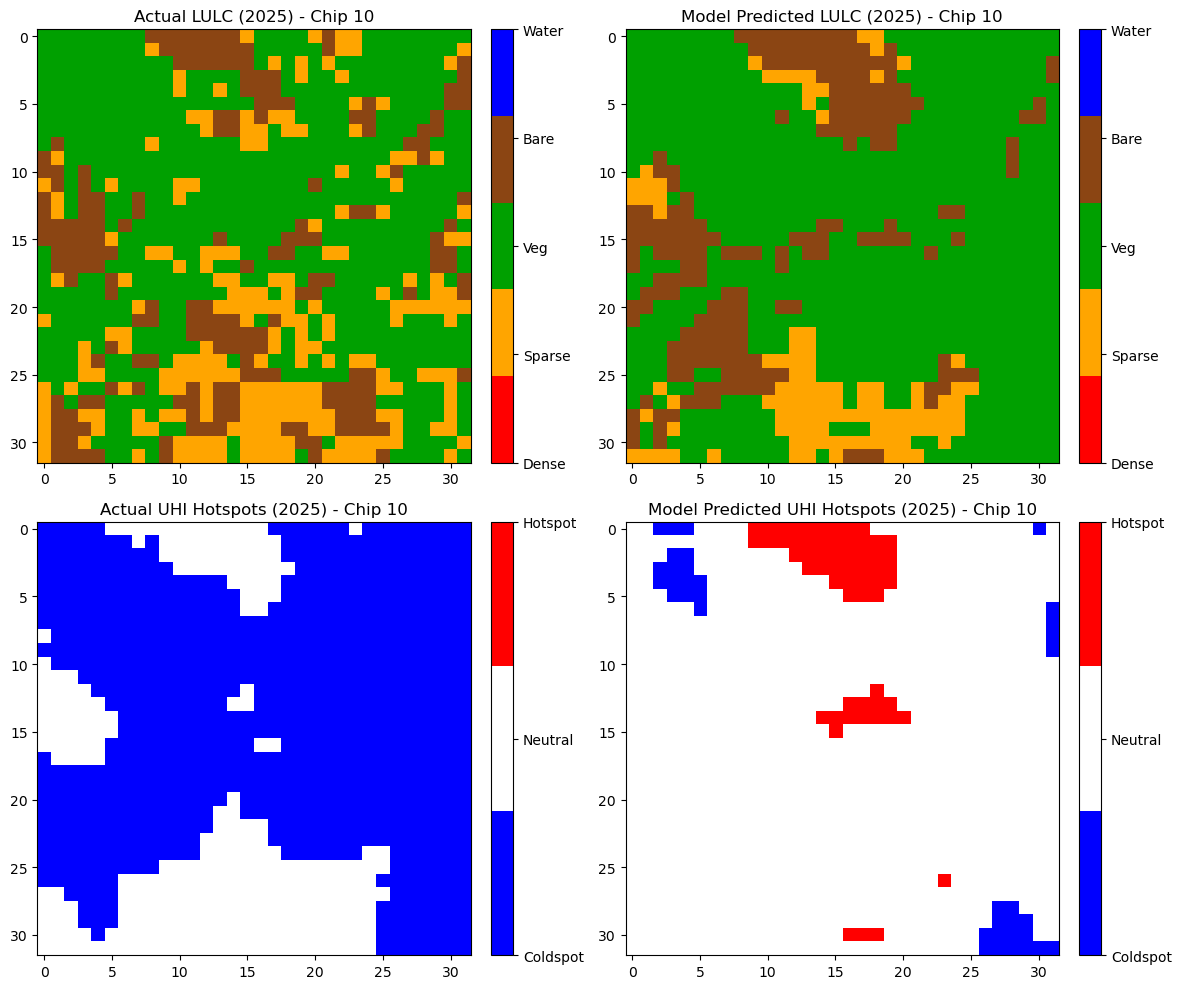

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import tensorflow as tf

# ==========================================
# 1. LOAD THE BEST SAVED MODEL
# ==========================================
model_path = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\Enugu_ConvLSTM_Best.h5"
trained_model = tf.keras.models.load_model(model_path)
print("Loaded optimal ConvLSTM weights successfully!")

# ==========================================
# 2. GENERATE PREDICTIONS FOR VALIDATION CHIPS
# ==========================================
# Predict using our validation subset (X_val)
preds = trained_model.predict(X_val)

# preds is a list: [lulc_probabilities, uhi_probabilities]
# Use np.argmax to convert the probability distributions back into strict integer classes (0-4 and 0-2)
pred_lulc_classes = np.argmax(preds[0], axis=-1)
pred_uhi_classes = np.argmax(preds[1], axis=-1)

print(f"Prediction Output Shapes -> LULC: {pred_lulc_classes.shape}, UHI: {pred_uhi_classes.shape}")

# ==========================================
# 3. VISUALIZE MODEL PREDICTION VS ACTUAL TRUTH
# ==========================================
lulc_colors = ListedColormap(['#FF0000', '#FFA500', '#00A000', '#8B4513', '#0000FF'])
uhi_colors = ListedColormap(['#0000FF', '#FFFFFF', '#FF0000'])

# Select a sample index from your validation batch to inspect
sample_idx = 10

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Row 1: LULC Comparison
im1 = axes[0, 0].imshow(Y_lulc_val[sample_idx], cmap=lulc_colors, vmin=0, vmax=4)
axes[0, 0].set_title(f"Actual LULC (2025) - Chip {sample_idx}")
cbar1 = plt.colorbar(im1, ax=axes[0, 0], ticks=[0, 1, 2, 3, 4], fraction=0.046, pad=0.04)
cbar1.ax.set_yticklabels(['Dense', 'Sparse', 'Veg', 'Bare', 'Water'])

im2 = axes[0, 1].imshow(pred_lulc_classes[sample_idx], cmap=lulc_colors, vmin=0, vmax=4)
axes[0, 1].set_title(f"Model Predicted LULC (2025) - Chip {sample_idx}")
cbar2 = plt.colorbar(im2, ax=axes[0, 1], ticks=[0, 1, 2, 3, 4], fraction=0.046, pad=0.04)
cbar2.ax.set_yticklabels(['Dense', 'Sparse', 'Veg', 'Bare', 'Water'])

# Row 2: UHI Hotspot Comparison
im3 = axes[1, 0].imshow(Y_uhi_val[sample_idx], cmap=uhi_colors, vmin=0, vmax=2)
axes[1, 0].set_title(f"Actual UHI Hotspots (2025) - Chip {sample_idx}")
cbar3 = plt.colorbar(im3, ax=axes[1, 0], ticks=[0, 1, 2], fraction=0.046, pad=0.04)
cbar3.ax.set_yticklabels(['Coldspot', 'Neutral', 'Hotspot'])

im4 = axes[1, 1].imshow(pred_uhi_classes[sample_idx], cmap=uhi_colors, vmin=0, vmax=2)
axes[1, 1].set_title(f"Model Predicted UHI Hotspots (2025) - Chip {sample_idx}")
cbar4 = plt.colorbar(im4, ax=axes[1, 1], ticks=[0, 1, 2], fraction=0.046, pad=0.04)
cbar4.ax.set_yticklabels(['Coldspot', 'Neutral', 'Hotspot'])

plt.tight_layout()
plt.show()

Initializing Spatial Edge-Growth ConvLSTM Pipeline...
Generating spatial chips and training ConvLSTM...
Epoch 1/60
38/38 [==============================] - 45s 1s/step - loss: 1.7476 - lulc_output_loss: 0.9769 - uhi_output_loss: 0.7707 - lulc_output_accuracy: 0.7482 - uhi_output_accuracy: 0.6999 - val_loss: 2.1229 - val_lulc_output_loss: 1.1625 - val_uhi_output_loss: 0.9604 - val_lulc_output_accuracy: 0.7286 - val_uhi_output_accuracy: 0.6374
Epoch 2/60
38/38 [==============================] - 38s 1s/step - loss: 1.2253 - lulc_output_loss: 0.5976 - uhi_output_loss: 0.6277 - lulc_output_accuracy: 0.8555 - uhi_output_accuracy: 0.7454 - val_loss: 1.9504 - val_lulc_output_loss: 1.0401 - val_uhi_output_loss: 0.9103 - val_lulc_output_accuracy: 0.7323 - val_uhi_output_accuracy: 0.6519
Epoch 3/60
38/38 [==============================] - 43s 1s/step - loss: 1.0639 - lulc_output_loss: 0.4743 - uhi_output_loss: 0.5896 - lulc_output_accuracy: 0.8683 - uhi_output_accuracy: 0.7593 - val_loss: 1.8070 

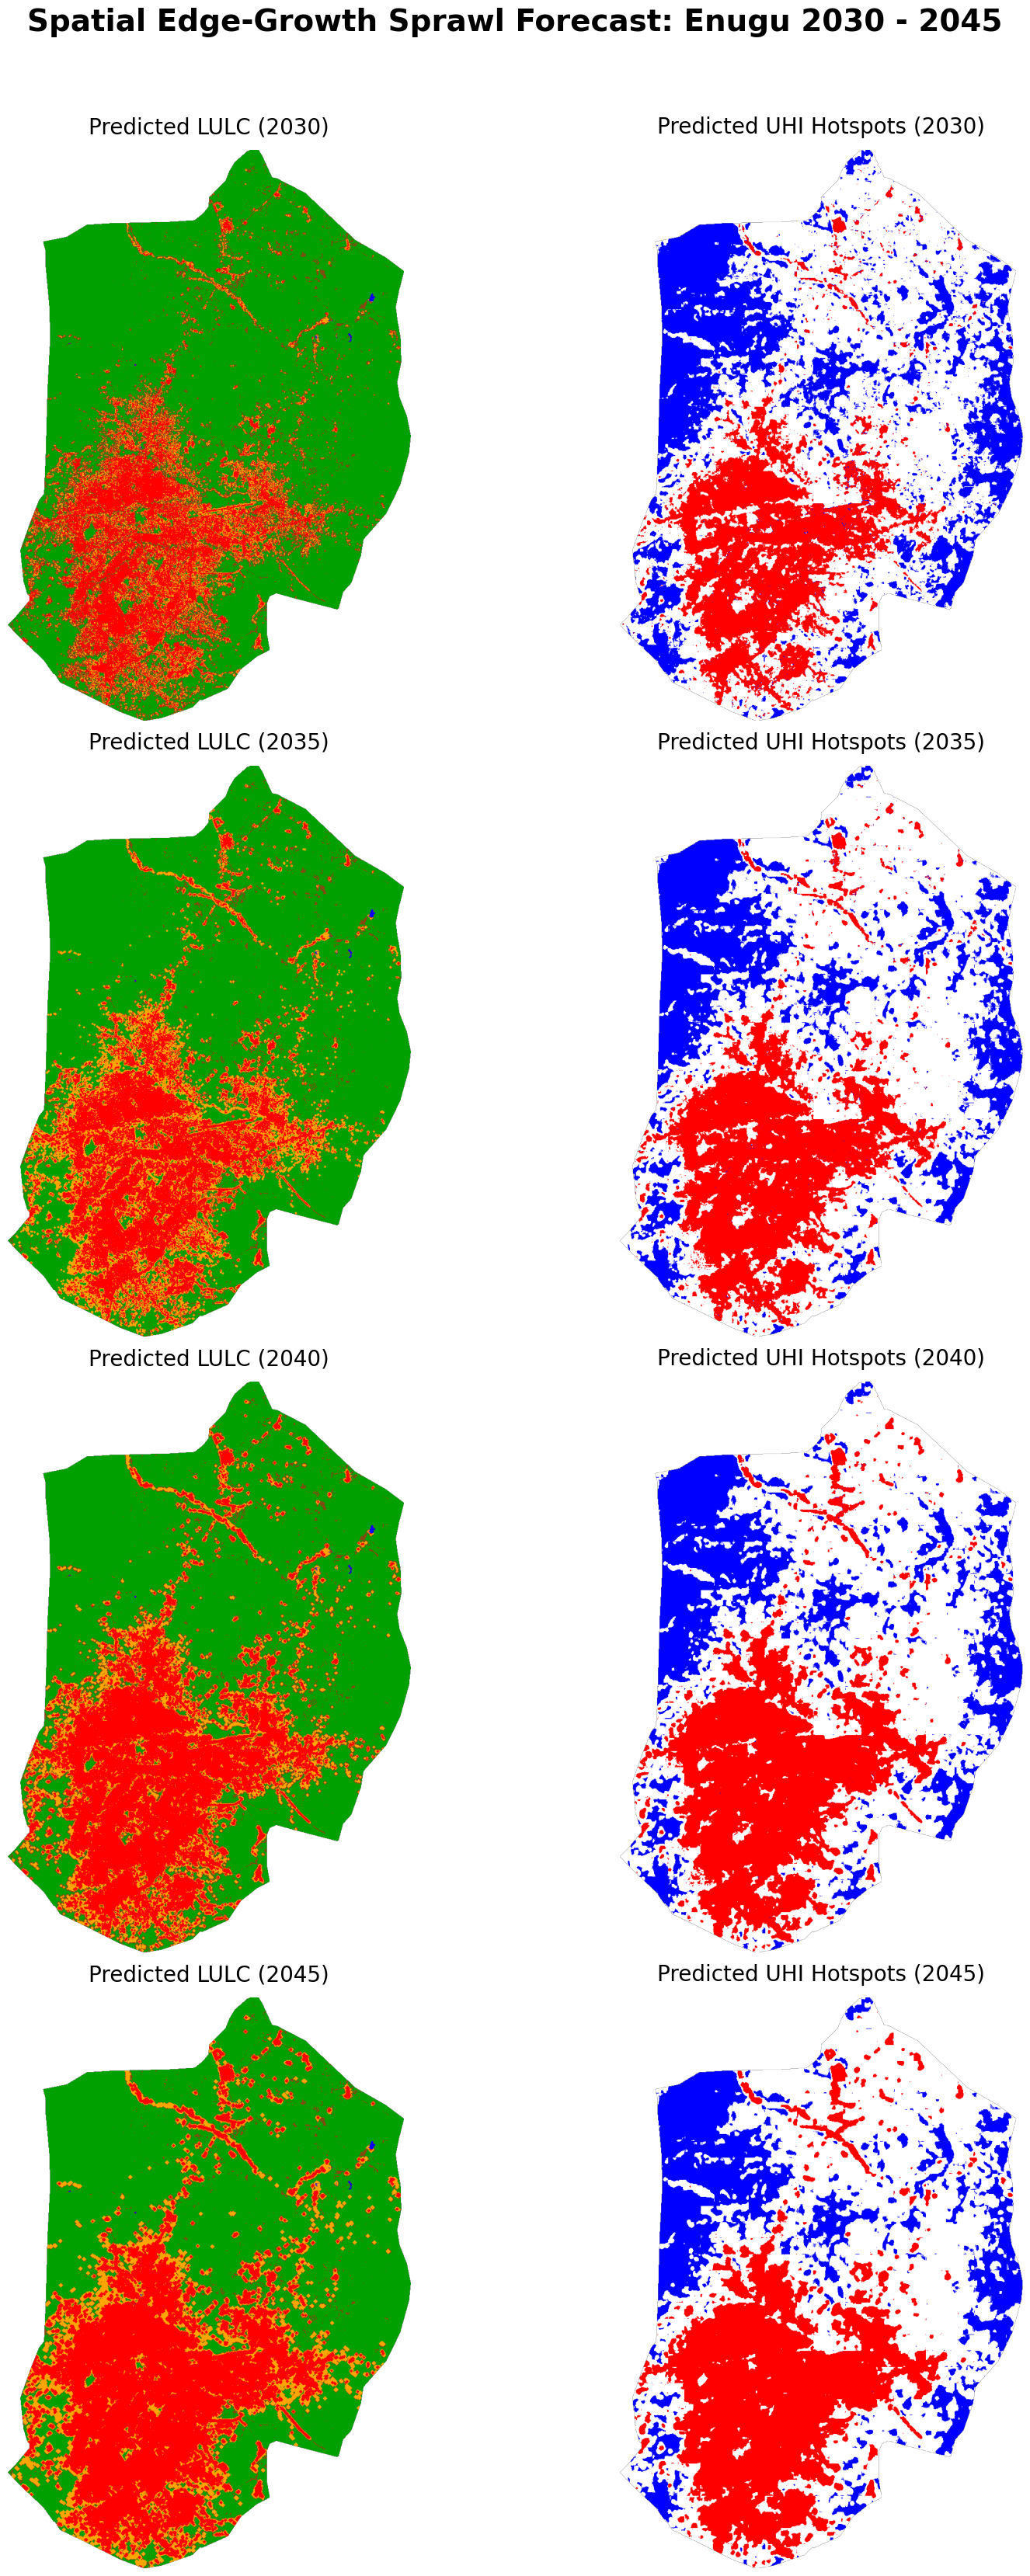

In [36]:
import os
import numpy as np
import rasterio
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.ndimage import binary_dilation
from tensorflow.keras import layers, models, utils
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

print("Initializing Spatial Edge-Growth ConvLSTM Pipeline...")
base_folder = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\"
years = [2000, 2010, 2015, 2020, 2024]
TOTAL_CITY_AREA_KM2 = 560.39

# ==========================================
# 1. SETUP & MASKING
# ==========================================
with rasterio.open(os.path.join(base_folder, "Enugu_2024_COMPLETE_ANALYSIS_STACK.tif")) as src:
    meta = src.meta.copy()
    height, width = src.shape
    valid_mask_full = src.read(15) 

inside_city_mask = ~np.isnan(valid_mask_full) & (valid_mask_full != 0)
pad_h, pad_w = (32 - (height % 32)) % 32, (32 - (width % 32)) % 32
padded_h, padded_w = height + pad_h, width + pad_w

# ==========================================
# 2. LOAD DATA
# ==========================================
temporal_tensor = np.zeros((5, padded_h, padded_w, 8), dtype=np.float32)
raw_lulc_history = np.zeros((5, padded_h, padded_w), dtype=np.float32)

for t, year in enumerate(years):
    with rasterio.open(os.path.join(base_folder, f"Enugu_{year}_COMPLETE_ANALYSIS_STACK.tif")) as src:
        lulc = np.nan_to_num(src.read(14), nan=2.0) 
        uhi_raw = np.nan_to_num(src.read(13), nan=0.0)
        
        uhi_c = np.zeros_like(uhi_raw)
        uhi_c[uhi_raw < -1.5] = 0
        uhi_c[(uhi_raw >= -1.5) & (uhi_raw <= 1.5)] = 1
        uhi_c[uhi_raw > 1.5] = 2
        
        lulc_padded = np.pad(lulc, ((0, pad_h), (0, pad_w)), mode='edge')
        uhi_padded = np.pad(uhi_c, ((0, pad_h), (0, pad_w)), mode='edge')
        
        raw_lulc_history[t] = lulc_padded
        temporal_tensor[t] = np.concatenate([utils.to_categorical(lulc_padded, 5), 
                                             utils.to_categorical(uhi_padded, 3)], axis=-1)

# ==========================================
# 3. CHIP EXTRACTION & TRAINING
# ==========================================
print("Generating spatial chips and training ConvLSTM...")
chip_size = 32
X_train, Y_lulc_train, Y_uhi_train, locked_coords = [], [], [], []

for y in range(0, padded_h, chip_size):
    for x in range(0, padded_w, chip_size):
        if np.any(inside_city_mask[y:min(y+chip_size, height), x:min(x+chip_size, width)]):
            X_train.append(temporal_tensor[0:4, y:y+chip_size, x:x+chip_size, :])
            Y_lulc_train.append(np.argmax(temporal_tensor[4, y:y+chip_size, x:x+chip_size, 0:5], axis=-1))
            Y_uhi_train.append(np.argmax(temporal_tensor[4, y:y+chip_size, x:x+chip_size, 5:8], axis=-1))
            locked_coords.append((y, x))

inputs = layers.Input(shape=(4, 32, 32, 8)) 
x = layers.ConvLSTM2D(filters=64, kernel_size=(3, 3), padding='same', return_sequences=True)(inputs)
x = layers.BatchNormalization()(x)
x = layers.ConvLSTM2D(filters=64, kernel_size=(3, 3), padding='same', return_sequences=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
lulc_out = layers.Conv2D(filters=5, kernel_size=(1, 1), activation='softmax', name='lulc_output')(x)
uhi_out = layers.Conv2D(filters=3, kernel_size=(1, 1), activation='softmax', name='uhi_output')(x)

model = models.Model(inputs=inputs, outputs=[lulc_out, uhi_out])
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.fit(np.array(X_train), {'lulc_output': np.array(Y_lulc_train), 'uhi_output': np.array(Y_uhi_train)}, 
          epochs=60, batch_size=16, validation_split=0.1, 
          callbacks=[EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])

# ==========================================
# 4. EDGE-GROWTH CA LOGIC & PREDICTION
# ==========================================
area_stats_lulc = []
area_stats_uhi = []

def predict_and_stitch(input_chips, year_name, previous_lulc_map):
    print(f"\nSimulating spatial edge-growth for {year_name}...")
    preds = model.predict(input_chips, batch_size=16)
    
    pred_lulc = np.argmax(preds[0], axis=-1)
    pred_uhi = np.argmax(preds[1], axis=-1)
    
    canvas_lulc = np.full((padded_h, padded_w), 2.0, dtype=np.float32)
    canvas_uhi = np.zeros((padded_h, padded_w), dtype=np.float32)
    
    for idx, (y, x) in enumerate(locked_coords):
        canvas_lulc[y:y+chip_size, x:x+chip_size] = pred_lulc[idx]
        canvas_uhi[y:y+chip_size, x:x+chip_size] = pred_uhi[idx]
        
    # --- 1. IRREVERSIBLE URBANIZATION ---
    canvas_lulc[previous_lulc_map == 4] = 4 # Water locked
    canvas_lulc[previous_lulc_map == 0] = 0 # Dense locked
    canvas_lulc[(previous_lulc_map == 1) & (canvas_lulc > 1)] = 1 # Sparse cannot degrade
    canvas_lulc[(previous_lulc_map == 3) & (canvas_lulc == 2)] = 3 # Bare soil cannot become veg

    # --- 2. PERIMETER EXPANSION (DILATION) ---
    # Densification: Sparse adjacent to Dense becomes Dense
    dense_fringe = binary_dilation((canvas_lulc == 0), iterations=1)
    canvas_lulc[dense_fringe & (canvas_lulc == 1)] = 0
    
    # Peri-urban Sprawl: Expand the urban boundary outward by 2 pixels (~60 meters every 5 years)
    urban_perimeter = binary_dilation((canvas_lulc == 0) | (canvas_lulc == 1), iterations=2)
    
    # Bare soil on the perimeter is developed into Sparse Urban
    canvas_lulc[urban_perimeter & (canvas_lulc == 3)] = 1
    # Vegetation on the perimeter is cleared into Bare Soil
    canvas_lulc[urban_perimeter & (canvas_lulc == 2)] = 3
    
    # --- 3. THERMAL COUPLING (UHI) ---
    # Force thermal logic to match physical concrete expansion
    canvas_uhi[(canvas_lulc == 0) & (canvas_uhi == 0)] = 2 # Dense urban cannot be a coldspot
    canvas_uhi[(canvas_lulc == 1) & (canvas_uhi == 0)] = 1 # Sparse urban is at least neutral
    canvas_uhi[(canvas_lulc == 2) & (canvas_uhi == 2)] = 0 # Vegetation cannot be a hotspot

    city_lulc = canvas_lulc[:height, :width].copy()
    city_uhi = canvas_uhi[:height, :width].copy()
    
    city_lulc[~inside_city_mask] = np.nan
    city_uhi[~inside_city_mask] = np.nan
    
    # --- 4. CALCULATE EXACT KM2 LANDMASS ---
    unique, counts = np.unique(city_lulc[~np.isnan(city_lulc)], return_counts=True)
    px_counts = dict(zip(unique, counts))
    multiplier = TOTAL_CITY_AREA_KM2 / sum(px_counts.values())
    
    area_stats_lulc.append({
        'Year': year_name,
        'Dense Urban': round(px_counts.get(0, 0) * multiplier, 2),
        'Sparse Urban': round(px_counts.get(1, 0) * multiplier, 2),
        'Vegetation': round(px_counts.get(2, 0) * multiplier, 2),
        'Bare Soil': round(px_counts.get(3, 0) * multiplier, 2),
        'Water': round(px_counts.get(4, 0) * multiplier, 2)
    })
    
    u_unique, u_counts = np.unique(city_uhi[~np.isnan(city_uhi)], return_counts=True)
    u_px = dict(zip(u_unique, u_counts))
    
    area_stats_uhi.append({
        'Year': year_name,
        'Coldspot': round(u_px.get(0, 0) * multiplier, 2),
        'Neutral': round(u_px.get(1, 0) * multiplier, 2),
        'Hotspot': round(u_px.get(2, 0) * multiplier, 2)
    })
    
    # Export
    meta.update(count=1, dtype=rasterio.float32, nodata=np.nan)
    with rasterio.open(os.path.join(base_folder, f"Enugu_{year_name}_PREDICTED_LULC.tif"), 'w', **meta) as dst:
        dst.write(city_lulc, 1)
    with rasterio.open(os.path.join(base_folder, f"Enugu_{year_name}_PREDICTED_UHI.tif"), 'w', **meta) as dst:
        dst.write(city_uhi, 1)
        
    return canvas_lulc, canvas_uhi

# ==========================================
# 5. RECURSIVE FORECAST EXECUTION
# ==========================================
X_2030_input = np.array([temporal_tensor[1:5, y:y+chip_size, x:x+chip_size, :] for y, x in locked_coords])
lulc_2030_canvas, uhi_2030_canvas = predict_and_stitch(X_2030_input, "2030", raw_lulc_history[4])

X_2035_input = []
for idx, (y, x) in enumerate(locked_coords):
    step_2030 = np.expand_dims(np.concatenate([utils.to_categorical(lulc_2030_canvas[y:y+chip_size, x:x+chip_size], 5), 
                                               utils.to_categorical(uhi_2030_canvas[y:y+chip_size, x:x+chip_size], 3)], axis=-1), axis=0)
    X_2035_input.append(np.concatenate([temporal_tensor[2:5, y:y+chip_size, x:x+chip_size, :], step_2030], axis=0))
lulc_2035_canvas, uhi_2035_canvas = predict_and_stitch(np.array(X_2035_input), "2035", lulc_2030_canvas)

X_2040_input = []
for idx, (y, x) in enumerate(locked_coords):
    step_2030 = np.expand_dims(np.concatenate([utils.to_categorical(lulc_2030_canvas[y:y+chip_size, x:x+chip_size], 5), utils.to_categorical(uhi_2030_canvas[y:y+chip_size, x:x+chip_size], 3)], axis=-1), axis=0)
    step_2035 = np.expand_dims(np.concatenate([utils.to_categorical(lulc_2035_canvas[y:y+chip_size, x:x+chip_size], 5), utils.to_categorical(uhi_2035_canvas[y:y+chip_size, x:x+chip_size], 3)], axis=-1), axis=0)
    X_2040_input.append(np.concatenate([temporal_tensor[3:5, y:y+chip_size, x:x+chip_size, :], step_2030, step_2035], axis=0))
lulc_2040_canvas, uhi_2040_canvas = predict_and_stitch(np.array(X_2040_input), "2040", lulc_2035_canvas)

X_2045_input = []
for idx, (y, x) in enumerate(locked_coords):
    step_2030 = np.expand_dims(np.concatenate([utils.to_categorical(lulc_2030_canvas[y:y+chip_size, x:x+chip_size], 5), utils.to_categorical(uhi_2030_canvas[y:y+chip_size, x:x+chip_size], 3)], axis=-1), axis=0)
    step_2035 = np.expand_dims(np.concatenate([utils.to_categorical(lulc_2035_canvas[y:y+chip_size, x:x+chip_size], 5), utils.to_categorical(uhi_2035_canvas[y:y+chip_size, x:x+chip_size], 3)], axis=-1), axis=0)
    step_2040 = np.expand_dims(np.concatenate([utils.to_categorical(lulc_2040_canvas[y:y+chip_size, x:x+chip_size], 5), utils.to_categorical(uhi_2040_canvas[y:y+chip_size, x:x+chip_size], 3)], axis=-1), axis=0)
    X_2045_input.append(np.concatenate([temporal_tensor[4:5, y:y+chip_size, x:x+chip_size, :], step_2030, step_2035, step_2040], axis=0))
lulc_2045_canvas, uhi_2045_canvas = predict_and_stitch(np.array(X_2045_input), "2045", lulc_2040_canvas)

# ==========================================
# 6. PRINT QUANTITATIVE TABLES
# ==========================================
print("\n--- FORECASTED LULC AREA (km²) ---")
df_lulc = pd.DataFrame(area_stats_lulc)
print(df_lulc.to_string(index=False))
df_lulc.to_csv(os.path.join(base_folder, "Enugu_Forecast_LULC_km2.csv"), index=False)

print("\n--- FORECASTED UHI HOTSPOTS (km²) ---")
df_uhi = pd.DataFrame(area_stats_uhi)
print(df_uhi.to_string(index=False))
df_uhi.to_csv(os.path.join(base_folder, "Enugu_Forecast_UHI_km2.csv"), index=False)

# ==========================================
# 7. FINAL VISUALIZATION
# ==========================================
print("\nRendering outward sprawl maps...")
lulc_colors = ListedColormap(['#FF0000', '#FFA500', '#00A000', '#8B4513', '#0000FF'])
uhi_colors = ListedColormap(['#0000FF', '#FFFFFF', '#FF0000'])

fig, axes = plt.subplots(4, 2, figsize=(18, 36))
fig.suptitle("Spatial Edge-Growth Sprawl Forecast: Enugu 2030 - 2045", fontsize=28, fontweight='bold', y=0.92)

canvases = [
    (lulc_2030_canvas, uhi_2030_canvas, "2030"),
    (lulc_2035_canvas, uhi_2035_canvas, "2035"),
    (lulc_2040_canvas, uhi_2040_canvas, "2040"),
    (lulc_2045_canvas, uhi_2045_canvas, "2045")
]

for i, (lulc_c, uhi_c, year_str) in enumerate(canvases):
    plot_lulc = lulc_c[:height, :width].copy()
    plot_lulc[~inside_city_mask] = np.nan
    plot_uhi = uhi_c[:height, :width].copy()
    plot_uhi[~inside_city_mask] = np.nan

    axes[i, 0].imshow(plot_lulc, cmap=lulc_colors, vmin=0, vmax=4)
    axes[i, 0].set_title(f"Predicted LULC ({year_str})", fontsize=20, pad=15)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(plot_uhi, cmap=uhi_colors, vmin=0, vmax=2)
    axes[i, 1].set_title(f"Predicted UHI Hotspots ({year_str})", fontsize=20, pad=15)
    axes[i, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

In [38]:
import os
import rasterio
import numpy as np
import pandas as pd

base_folder = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\"
timeline = [2000, 2010, 2015, 2020, 2024, 2030, 2035, 2040, 2045]
TOTAL_CITY_AREA_KM2 = 560.39
KM2_TO_HECTARES = 100

print("Extracting Spatial Metrics & Calculating Rates of Change (2000 - 2045)...")
results = []
previous_data = None

for i, year in enumerate(timeline):
    is_historical = year <= 2024
    
    if is_historical:
        file_path = os.path.join(base_folder, f"Enugu_{year}_COMPLETE_ANALYSIS_STACK.tif")
    else:
        file_path = os.path.join(base_folder, f"Enugu_{year}_PREDICTED_LULC.tif")
        
    try:
        with rasterio.open(file_path) as src:
            if is_historical:
                # 7: NDVI, 8: NDBI, 9: BSI, 14: LULC, 15: VALID_MASK
                ndvi = src.read(7)
                ndbi = src.read(8)
                bsi = src.read(9)
                lulc = src.read(14)
                valid_mask = src.read(15)
                
                # Apply mask to calculate true means
                valid_pixels = (~np.isnan(valid_mask)) & (valid_mask != 0)
                mean_ndvi = np.nanmean(ndvi[valid_pixels])
                mean_ndbi = np.nanmean(ndbi[valid_pixels])
                mean_bsi = np.nanmean(bsi[valid_pixels])
                
                lulc_valid = lulc[valid_pixels]
            else:
                # Predicted maps only contain the LULC band
                lulc = src.read(1)
                valid_pixels = ~np.isnan(lulc)
                lulc_valid = lulc[valid_pixels]
                
                # Spectral wavelengths do not exist in future categorical predictions
                mean_ndvi, mean_ndbi, mean_bsi = np.nan, np.nan, np.nan
                
        # Count pixels for LULC classes
        unique, counts = np.unique(lulc_valid, return_counts=True)
        px_counts = dict(zip(unique, counts))
        
        # Calculate dynamic pixel resolution based on exact total city area
        total_pixels = sum(px_counts.values())
        multiplier_km2 = TOTAL_CITY_AREA_KM2 / total_pixels
        
        built_up_km2 = (px_counts.get(0, 0) + px_counts.get(1, 0)) * multiplier_km2
        veg_km2 = px_counts.get(2, 0) * multiplier_km2
        bare_km2 = px_counts.get(3, 0) * multiplier_km2
        
        # Current Year Data Dictionary
        current_data = {
            'Year': year,
            'Built-up Area (km²)': round(built_up_km2, 2),
            'Built-up Area (ha)': round(built_up_km2 * KM2_TO_HECTARES, 2),
            'Vegetation (km²)': round(veg_km2, 2),
            'Vegetation (ha)': round(veg_km2 * KM2_TO_HECTARES, 2),
            'Bare Soil (km²)': round(bare_km2, 2),
            'Bare Soil (ha)': round(bare_km2 * KM2_TO_HECTARES, 2),
            'Mean NDVI': round(mean_ndvi, 4) if not np.isnan(mean_ndvi) else 'N/A',
            'Mean NDBI': round(mean_ndbi, 4) if not np.isnan(mean_ndbi) else 'N/A',
            'Mean BSI': round(mean_bsi, 4) if not np.isnan(mean_bsi) else 'N/A'
        }
        
        # Calculate Change Metrics (Percentage & Rate)
        if previous_data is not None:
            time_gap = year - previous_data['Year']
            
            # Built-up Change
            bu_diff = built_up_km2 - previous_data['built_up_km2_raw']
            current_data['Built-up Change (%)'] = round((bu_diff / previous_data['built_up_km2_raw']) * 100, 2)
            current_data['Built-up Rate (km²/yr)'] = round(bu_diff / time_gap, 2)
            
            # Vegetation Change
            veg_diff = veg_km2 - previous_data['veg_km2_raw']
            current_data['Veg Change (%)'] = round((veg_diff / previous_data['veg_km2_raw']) * 100, 2)
            current_data['Veg Rate (km²/yr)'] = round(veg_diff / time_gap, 2)
            
            # Bare Soil Change
            bare_diff = bare_km2 - previous_data['bare_km2_raw']
            current_data['Bare Soil Change (%)'] = round((bare_diff / previous_data['bare_km2_raw']) * 100, 2) if previous_data['bare_km2_raw'] > 0 else 0
            current_data['Bare Rate (km²/yr)'] = round(bare_diff / time_gap, 2)
            
        else:
            # First year (2000) acts as the baseline
            current_data['Built-up Change (%)'] = '-'
            current_data['Built-up Rate (km²/yr)'] = '-'
            current_data['Veg Change (%)'] = '-'
            current_data['Veg Rate (km²/yr)'] = '-'
            current_data['Bare Soil Change (%)'] = '-'
            current_data['Bare Rate (km²/yr)'] = '-'
            
        # Store exact raw values to ensure mathematical precision in next iteration
        previous_data = {
            'Year': year,
            'built_up_km2_raw': built_up_km2,
            'veg_km2_raw': veg_km2,
            'bare_km2_raw': bare_km2
        }
        
        results.append(current_data)
        
    except Exception as e:
        print(f"Failed to process Year {year}: {e}")

# Generate and display the final comprehensive table
df_metrics = pd.DataFrame(results)
print("\n--- SPATIAL DYNAMICS & RATE OF CHANGE TABLE (2000 - 2045) ---")
print(df_metrics.to_string(index=False))

# Export to CSV for thesis integration
output_csv = os.path.join(base_folder, "Enugu_Comprehensive_Spatial_Metrics.csv")
df_metrics.to_csv(output_csv, index=False)
print(f"\nExtensive quantitative table exported to: {output_csv}")

Extracting Spatial Metrics & Calculating Rates of Change (2000 - 2045)...

--- SPATIAL DYNAMICS & RATE OF CHANGE TABLE (2000 - 2045) ---
 Year  Built-up Area (km²)  Built-up Area (ha)  Vegetation (km²)  Vegetation (ha)  Bare Soil (km²)  Bare Soil (ha) Mean NDVI Mean NDBI Mean BSI Built-up Change (%) Built-up Rate (km²/yr) Veg Change (%) Veg Rate (km²/yr) Bare Soil Change (%) Bare Rate (km²/yr)
 2000                47.43             4743.31            423.59         42358.92            89.12         8911.93    0.4199    0.0053   0.0514                   -                      -              -                 -                    -                  -
 2010                22.14             2214.22            506.21         50620.75            30.59         3058.99    0.5696   -0.0652  -0.0208              -53.32                  -2.53           19.5              8.26               -65.68              -5.85
 2015                55.10             5510.41            441.98         44197.87  

In [39]:
import os
import rasterio
import numpy as np
import pandas as pd

base_folder = "C:\\Users\\PC\\Documents\\MSc_Enugu_Data\\"
timeline = [2000, 2010, 2015, 2020, 2024, 2030, 2035, 2040, 2045]
TOTAL_CITY_AREA_KM2 = 560.39
KM2_TO_HECTARES = 100

print("Extracting Thermal Metrics & UHI Expansion Rates (2000 - 2045)...")
results = []
previous_hotspot_km2 = None
previous_year = None

for year in timeline:
    is_historical = year <= 2024
    
    if is_historical:
        # 16-Band Stack for historical data
        file_path = os.path.join(base_folder, f"Enugu_{year}_COMPLETE_ANALYSIS_STACK.tif")
    else:
        # Single-Band Categorical map for forecasts
        file_path = os.path.join(base_folder, f"Enugu_{year}_PREDICTED_UHI.tif")
        
    try:
        with rasterio.open(file_path) as src:
            if is_historical:
                lst = src.read(12)      # Band 12 is LST_C
                uhi_raw = src.read(13)  # Band 13 is UHI Anomaly
                valid_mask = src.read(15)
                
                # Apply mask to calculate true spatial temperatures
                valid_pixels = (~np.isnan(valid_mask)) & (valid_mask != 0)
                mean_lst = np.nanmean(lst[valid_pixels])
                max_lst = np.nanmax(lst[valid_pixels])
                min_lst = np.nanmin(lst[valid_pixels])
                
                uhi_valid = uhi_raw[valid_pixels]
                
                # Categorize historical continuous anomaly into classes
                uhi_classes = np.zeros_like(uhi_valid)
                uhi_classes[uhi_valid < -1.5] = 0
                uhi_classes[(uhi_valid >= -1.5) & (uhi_valid <= 1.5)] = 1
                uhi_classes[uhi_valid > 1.5] = 2
                
            else:
                # Predicted maps already contain classes 0, 1, 2
                uhi_classes_img = src.read(1)
                valid_pixels = ~np.isnan(uhi_classes_img)
                uhi_classes = uhi_classes_img[valid_pixels]
                
                # Continuous degrees do not exist in categorical forecasts
                mean_lst, max_lst, min_lst = np.nan, np.nan, np.nan
                
        # Count pixels for UHI classes
        unique, counts = np.unique(uhi_classes, return_counts=True)
        px_counts = dict(zip(unique, counts))
        
        # Calculate dynamic pixel resolution based on total city area
        total_pixels = sum(px_counts.values())
        multiplier_km2 = TOTAL_CITY_AREA_KM2 / total_pixels
        
        cold_km2 = px_counts.get(0, 0) * multiplier_km2
        neutral_km2 = px_counts.get(1, 0) * multiplier_km2
        hot_km2 = px_counts.get(2, 0) * multiplier_km2
        
        # Build Row Data
        row = {
            'Year': year,
            'Mean LST (°C)': round(mean_lst, 2) if not np.isnan(mean_lst) else 'N/A',
            'Max LST (°C)': round(max_lst, 2) if not np.isnan(max_lst) else 'N/A',
            'Min LST (°C)': round(min_lst, 2) if not np.isnan(min_lst) else 'N/A',
            'Coldspot (km²)': round(cold_km2, 2),
            'Coldspot (ha)': round(cold_km2 * KM2_TO_HECTARES, 2),
            'Neutral (km²)': round(neutral_km2, 2),
            'Neutral (ha)': round(neutral_km2 * KM2_TO_HECTARES, 2),
            'Hotspot (km²)': round(hot_km2, 2),
            'Hotspot (ha)': round(hot_km2 * KM2_TO_HECTARES, 2)
        }
        
        # Calculate Hotspot Expansion Rate
        if previous_hotspot_km2 is not None:
            time_gap = year - previous_year
            hot_diff = hot_km2 - previous_hotspot_km2
            
            row['Hotspot Change (%)'] = round((hot_diff / previous_hotspot_km2) * 100, 2) if previous_hotspot_km2 > 0 else 0
            row['Hotspot Rate (km²/yr)'] = round(hot_diff / time_gap, 2)
        else:
            row['Hotspot Change (%)'] = '-'
            row['Hotspot Rate (km²/yr)'] = '-'
            
        previous_hotspot_km2 = hot_km2
        previous_year = year
        results.append(row)
        
    except Exception as e:
        print(f"Failed to process Year {year}: {e}")

# Generate Table and Export
df_uhi_metrics = pd.DataFrame(results)
print("\n--- LST METRICS & UHI SPATIAL EXPANSION TABLE (2000 - 2045) ---")
print(df_uhi_metrics.to_string(index=False))

output_csv = os.path.join(base_folder, "Enugu_Comprehensive_UHI_Metrics.csv")
df_uhi_metrics.to_csv(output_csv, index=False)
print(f"\nExtensive UHI thermal table exported to: {output_csv}")

Extracting Thermal Metrics & UHI Expansion Rates (2000 - 2045)...

--- LST METRICS & UHI SPATIAL EXPANSION TABLE (2000 - 2045) ---
 Year Mean LST (°C) Max LST (°C) Min LST (°C)  Coldspot (km²)  Coldspot (ha)  Neutral (km²)  Neutral (ha)  Hotspot (km²)  Hotspot (ha) Hotspot Change (%) Hotspot Rate (km²/yr)
 2000     36.849998    50.349998        27.35          178.32       17832.10         214.59      21458.51         167.48      16748.39                  -                     -
 2010     34.189999    46.869999        25.92          337.93       33792.82         115.08      11507.92         107.38      10738.26             -35.88                 -6.01
 2015     35.919998    45.040001        27.65          139.11       13911.27         247.17      24716.89         174.11      17410.84              62.14                 13.35
 2020     38.150002    47.880001        26.52          135.33       13532.88         264.75      26474.57         160.32      16031.56              -7.92            